# 00 — ISSP 2022


In [1]:
import os
import sys
from pathlib import Path

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root found at or above {Path.cwd()}")

PAPER_DIR = CODE_DIR / "papers" / "pm"
SRC_DIR = PAPER_DIR / "src"
DATA_DIR = SRC_DIR / "data"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)


In [2]:
import pandas as pd
from data.persona_spec import load_persona_spec

spec = load_persona_spec(DATA_DIR / "persona_spec.yaml")
df = pd.read_parquet(DATA_DIR / "issp2022" / "issp2022_US_long.parquet")

print(f"Shape: {df.shape} | Respondents: {df['CASEID'].nunique():,} | Questions: {df['v'].nunique()}")
df.head(3)


Shape: (51303, 30) | Respondents: 1,126 | Questions: 55


,CASEID,country,gender,age,region,education,family_income,religion,religious_attendance,political_party,...,occupation,v,label,question,type,reversed,option_codes,option_texts,answer_code,answer_text
0,2022008400000002,United States,Male,65+,New England,Master's degree,NaN,Catholic,Once or twice a year,Democrat,...,Sales and marketing managers,v1,Q1a Working mom can establish as warm relation...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",3,Neither agree nor disagree
1,2022008400000002,United States,Male,65+,New England,Master's degree,NaN,Catholic,Once or twice a year,Democrat,...,Sales and marketing managers,v2,Q1b Pre-school child is likely to suffer if mo...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",2,Agree
2,2022008400000002,United States,Male,65+,New England,Master's degree,NaN,Catholic,Once or twice a year,Democrat,...,Sales and marketing managers,v3,Q1c Family life suffers when woman has full-ti...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",4,Disagree


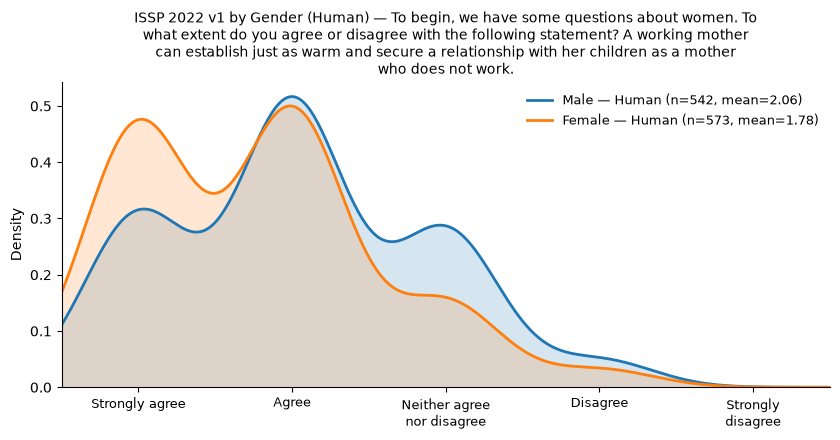

In [3]:
import textwrap
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

v1 = df[(df["v"] == "v1") & df["gender"].notna()]
if v1.empty:
    raise ValueError("No non-missing gender rows for v1")

v1_codes = np.array([int(c) for c in v1["option_codes"].iloc[0]], dtype=float)
v1_opts = list(v1["option_texts"].iloc[0])
v1_genders = [g for g in spec["gender"].levels if g in set(v1["gender"])]
v1_question = v1["question"].iloc[0]

v1_counts = pd.crosstab(v1["gender"], v1["answer_code"]).reindex(index=v1_genders, columns=v1_codes.astype(int), fill_value=0)
v1_human_probs = {g: (v1_counts.loc[g].to_numpy(dtype=float) / v1_counts.loc[g].sum()) for g in v1_genders}


def smooth_kde(xs, codes, probs, bw=0.35):
    return sum(p * norm.pdf(xs, loc=c, scale=bw) for c, p in zip(codes, probs, strict=True))


def plot_v1_gender(human_probs, model_probs=None, model_label="Model", bw=0.35):
    xs = np.linspace(v1_codes.min() - 0.5, v1_codes.max() + 0.5, 400)
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for g, color in zip(v1_genders, colors):
        hp = human_probs[g]
        hy = smooth_kde(xs, v1_codes, hp, bw=bw)
        hmean = float(np.dot(v1_codes, hp))
        ax.plot(xs, hy, lw=2, color=color, label=f"{g} — Human (n={v1_counts.loc[g].sum()}, mean={hmean:.2f})")
        ax.fill_between(xs, hy, alpha=0.18, color=color)

        if model_probs is not None:
            mp = np.asarray(model_probs[g], dtype=float)
            my = smooth_kde(xs, v1_codes, mp, bw=bw)
            mmean = float(np.dot(v1_codes, mp))
            ax.plot(xs, my, lw=2, ls="--", color=color, label=f"{g} — {model_label} (mean={mmean:.2f})")

    ax.set_xticks(v1_codes)
    ax.set_xticklabels([textwrap.fill(o, 15) for o in v1_opts], fontsize=9)
    ax.set_xlim(v1_codes.min() - 0.5, v1_codes.max() + 0.5)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Density")
    title = f"ISSP 2022 v1 by Gender ({model_label} vs Human)" if model_probs is not None else "ISSP 2022 v1 by Gender (Human)"
    ax.set_title(textwrap.fill(f"{title} — {v1_question}", 85), fontsize=10)
    ax.legend(frameon=False, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_v1_gender(v1_human_probs)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Prompt preview (76 tokens; state 4 tokens (no truncation, strict=True)):
<|fim_prefix|>
Gender: Male
<|fim_middle|>
To begin, we have some questions about women. To what extent do you agree or disagree with the following statement? A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.
<|box_start|>Strongly agree<|box_end|>
<|box_start|>Agree<|box_end|>
<|box_start|>Neither agree nor disagree<|box_end|>
<|box_start|>Disagree<|box_end|>
<|box_start|>Strongly disagree<|box_end|>
<|fim_suffix|>

Male   | Human: [26.9%, 44.5%, 24.4%,  4.2%,  0.0%] | Kev-0.8B: [ 2.2%,  2.3%, 71.4%, 20.4%,  3.8%]
Female | Human: [41.0%, 42.9%, 13.3%,  2.8%,  0.0%] | Kev-0.8B: [ 1.3%,  1.6%, 86.0%,  9.8%,  1.2%]


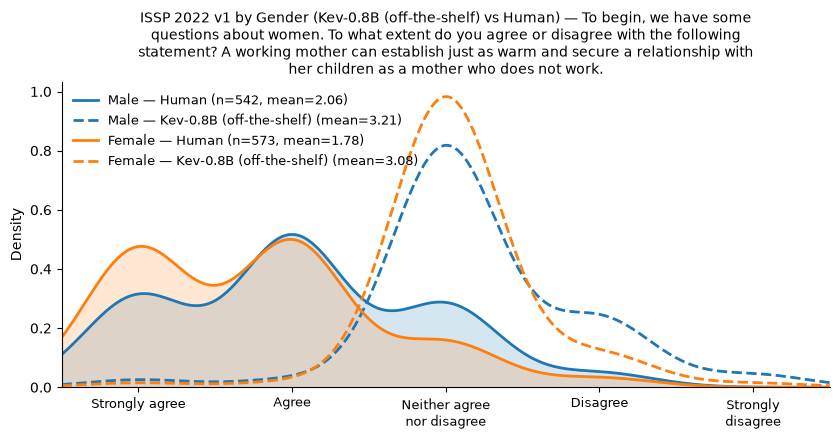

In [4]:
import torch
import torch.nn.functional as F
from models.kev_pointer import KevPointerModel

BASE_MODEL = "jaredpalmer/kev-0.8b"
DEVICE = torch.device("cuda")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required to run Kev-0.8B")

model = KevPointerModel.load(BASE_MODEL, DEVICE)
model.eval()

v1_type = v1["type"].iloc[0]


def build_v1_gender_views():
    views = {}
    for g in v1_genders:
        views[g] = {
            "state": f"{spec['gender'].prompt}: {g}",
            "questions": {
                "v1": {
                    "type": v1_type,
                    "instructions": v1_question,
                    "criteria": v1_opts,
                    "target": {str(i): float(p) for i, p in enumerate(v1_human_probs[g])},
                }
            },
        }
    return views


@torch.no_grad()
def predict_v1_gender(model):
    views = build_v1_gender_views()
    prepared = [model.prepare(views[g])[0] for g in v1_genders]
    logits_batch = model.forward(prepared)
    probs = {}
    for g, q_logits in zip(v1_genders, logits_batch, strict=True):
        p_vec = F.softmax(q_logits[0].float(), dim=-1).cpu().numpy()
        if len(p_vec) != len(v1_opts):
            raise ValueError(f"{g}: expected {len(v1_opts)} option probs, got {len(p_vec)}")
        probs[g] = p_vec
    return views, probs


v1_views, v1_base_probs = predict_v1_gender(model)
header, preview = model.encoder.preview(v1_views[v1_genders[0]])
print(f"Prompt preview ({header}):\n{preview}\n")
for g in v1_genders:
    h_str = ", ".join(f"{100 * x:4.1f}%" for x in v1_human_probs[g])
    m_str = ", ".join(f"{100 * x:4.1f}%" for x in v1_base_probs[g])
    print(f"{g:<6} | Human: [{h_str}] | Kev-0.8B: [{m_str}]")

plot_v1_gender(v1_human_probs, v1_base_probs, model_label="Kev-0.8B (off-the-shelf)")


## IID Training

In [5]:
import pprint
from data import build_records, load_issp_df

train_df = load_issp_df(["2022"], spec=spec)
train_records = build_records(train_df, spec=spec, include_country=False)

print(
    f"Records: {len(train_records):,} | "
    f"Respondents: {train_df['CASEID'].nunique():,} | "
    f"Questions: {train_df['v'].nunique()}"
)
print("\n--- Raw record[0] ---")
pprint.pprint(train_records[0], sort_dicts=False)


Records: 51,303 | Respondents: 1,126 | Questions: 55

--- Raw record[0] ---
{'qid': 'issp2022:v1',
 'dataset': 'issp2022',
 'v': 'v1',
 'CASEID': 2022008400000002,
 'type': 'score',
 'question': 'To begin, we have some questions about women. To what extent do '
             'you agree or disagree with the following statement? A working '
             'mother can establish just as warm and secure a relationship with '
             'her children as a mother who does not work.',
 'option_texts': ['Strongly agree',
                  'Agree',
                  'Neither agree nor disagree',
                  'Disagree',
                  'Strongly disagree'],
 'option_descriptions': None,
 'personas': {'gender': 'Male',
              'age': '65+',
              'region': 'New England',
              'education': "Master's degree",
              'religion': 'Catholic',
              'religious_attendance': 'Once or twice a year',
              'political_party': 'Democrat',
              'mar

In [6]:
import random
from data import make_view, prompt_map_from_spec

In [7]:
sample_view = make_view(
    train_records[0],
    prompt_map=prompt_map_from_spec(spec),
    rng=random.Random(0),
)

print("--- Kev view dict ---")
pprint.pprint(sample_view, sort_dicts=False)

header, preview = model.encoder.preview(sample_view)
print(f"\n--- Exact model input ({header}) ---")
print(preview)


--- Kev view dict ---
{'state': 'Did you vote in the last general election?: Yes\n'
          'Household size: 2\n'
          'Gender: Male\n'
          'Personal income: No income\n'
          'Region: New England\n'
          'From what countries or part of the world did your ancestors come?: '
          'Austria; Ireland\n'
          'Which best describes where you live?: The suburbs or outskirts of a '
          'big city\n'
          "Education: Master's degree\n"
          'How often do you attend religious services?: Once or twice a year\n'
          'Occupation: Sales and marketing managers\n'
          "Spouse or partner's employment status: Retired\n"
          'Political party: Democrat\n'
          'Marital status: Married\n'
          'Employment status: Retired\n'
          'Religion: Catholic\n'
          'Age: 65+\n'
          "Spouse or partner's education: Bachelor's degree\n"
          'Sector of employment: Private employer',
 'questions': {'issp2022:v1': {'type': '

In [8]:
from training import IIDTrainer, free_gpu


def eval_v1_marginals(m, step, epoch):
    _, probs = predict_v1_gender(m)
    kls = {}
    for g in v1_genders:
        h = v1_human_probs[g]
        p = np.clip(probs[g], 1e-12, 1.0)
        nz = h > 0
        kls[f"kl_{g.lower()}"] = float(np.sum(h[nz] * np.log2(h[nz] / p[nz])))
    mean_kl = float(np.mean(list(kls.values())))
    parts = " | ".join(f"{g}: {kls[f'kl_{g.lower()}']:.4f}" for g in v1_genders)
    print(f"[eval step={step:4d} ep={epoch}] v1 KL (bits) — mean: {mean_kl:.4f} | {parts}")
    return {
        "v1_mean_kl": mean_kl,
        **kls,
        "probs": {g: probs[g].tolist() for g in v1_genders},
    }


# Release the off-the-shelf inference model before building the trainable LoRA model
model = None
free_gpu()

trainer = IIDTrainer(
    train_records=train_records,
    spec=spec,
    base_model=BASE_MODEL,
    lora_rank=64,
    epochs=1,
    lr=1e-4,
    questions_per_step=128,
    gradient_checkpointing=False,
    eval_fn=eval_v1_marginals,
    eval_every=50,
    eval_at_start=True,
    seed=0,
)
trainer.find_max_micro_batch_size(headroom_gb=2.0)
pprint.pprint(trainer.describe(), sort_dicts=False)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Probing max micro_batch_size (1..128) | worst_seq=330 tok (qid=issp2022:v52) | free=25.63 GiB, adam=0.33 GiB, headroom=2.00 GiB -> limit=24.94 GiB (gc=False)
  micro_batch_size=  1 -> ok               (peak=2.64 GiB)
  micro_batch_size=  2 -> ok               (peak=3.51 GiB)
  micro_batch_size=  4 -> ok               (peak=5.26 GiB)
  micro_batch_size=  8 -> ok               (peak=8.60 GiB)
  micro_batch_size= 16 -> ok               (peak=15.47 GiB)


[W1125 22:46:42.247161872 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 153092096 bytes (free: 160825344, total: 33710276608).
[W1125 22:46:42.305256714 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 153092096 bytes (free: 129368064, total: 33710276608).
[W1125 22:46:42.305348864 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 153092096 bytes (free: 129368064, total: 33710276608).


  micro_batch_size= 32 -> oom              (peak=OOM)
  micro_batch_size= 24 -> ok               (peak=22.25 GiB)
  micro_batch_size= 28 -> exceeds_headroom (peak=25.82 GiB)
  micro_batch_size= 26 -> ok               (peak=24.14 GiB)
  micro_batch_size= 27 -> ok               (peak=24.86 GiB)
=> applied micro_batch_size=27 (worst-case peak=24.86 GiB <= 24.94 GiB)
{'trainer': 'iid',
 'init_from': 'jaredpalmer/kev-0.8b',
 'lora_rank': 64,
 'n_train_records': 51303,
 'epochs': 1,
 'steps_per_epoch': [401],
 'total_steps': 401,
 'lr': 0.0001,
 'lr_schedule': 'onecycle',
 'min_lr': 4e-10,
 'weight_decay': 0.01,
 'pct_start': 0.1,
 'weights_dtype': 'bf16',
 'use_bf16': True,
 'gradient_checkpointing': False,
 'seed': 0,
 'questions_per_step': 128,
 'micro_batch_size': 27,
 'max_chars_per_microbatch': None,
 'sort_within_step': True}


In [10]:
trainer.micro_batch_size

27

In [11]:
history = trainer.train()


[eval step=   0 ep=0] v1 KL (bits) — mean: 3.1524 | Male: 2.4553 | Female: 3.8495


iid:   0%|          | 0/401 [00:00<?, ?it/s]

[W1125 22:48:37.903488149 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 115343360 bytes (free: 120848384, total: 33710276608).


[eval step=  50 ep=1] v1 KL (bits) — mean: 0.0515 | Male: 0.0564 | Female: 0.0467


KeyboardInterrupt: 

In [ ]:
# Training curve & v1 marginal KL every 50 steps
eval_steps = [e["step"] for e in history["evals"]]
v1_mean_kls = [e["metrics"]["v1_mean_kl"] for e in history["evals"]]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))

axes[0].plot(history["steps"], history["train_kl"], lw=1.5, label="Train KL (bits)")
axes[0].plot(history["steps"], history["train_ce"], lw=1.5, alpha=0.6, label="Train CE (nats)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss")
axes[0].set_title("IID Training Curve — ISSP 2022")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(eval_steps, v1_mean_kls, marker="o", lw=2, color="black", label="Mean v1 KL")
for g in v1_genders:
    g_kls = [e["metrics"][f"kl_{g.lower()}"] for e in history["evals"]]
    axes[1].plot(eval_steps, g_kls, marker="o", lw=1.5, ls="--", label=f"{g} v1 KL")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("KL Divergence (bits)")
axes[1].set_title("v1 Marginal KL by Gender (every 50 steps)")
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Post-training v1 marginal by gender vs Human
v1_iid_probs = {g: np.asarray(history["evals"][-1]["metrics"]["probs"][g], dtype=float) for g in v1_genders}
for g in v1_genders:
    h_str = ", ".join(f"{100 * x:4.1f}%" for x in v1_human_probs[g])
    m_str = ", ".join(f"{100 * x:4.1f}%" for x in v1_iid_probs[g])
    print(f"{g:<6} | Human: [{h_str}] | Kev-0.8B (IID): [{m_str}]")

plot_v1_gender(v1_human_probs, v1_iid_probs, model_label="Kev-0.8B (IID)")
